In [1]:
from torchvision import datasets
from torchvision.transforms import ToTensor

train = datasets.FashionMNIST(root="../data", train=True, download=True, transform=ToTensor())
test = datasets.FashionMNIST(root="../data", train=False, download=True, transform=ToTensor())

In [2]:
assert len(train) == 60000
assert len(test) == 10000

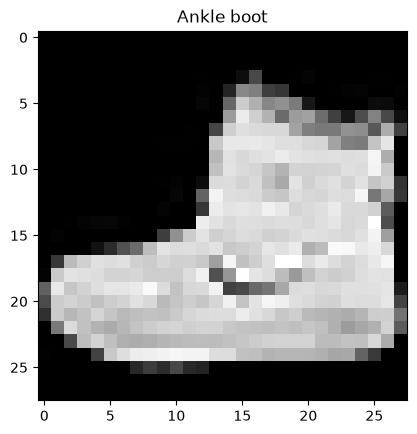

In [3]:
import matplotlib.pyplot as plt

img, label = train[0]


assert img[0].shape == (28, 28)

plt.title(train.classes[label])
plt.imshow(img[0], cmap="gray")
plt.show()


In [4]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train, batch_size=64, shuffle=True)
test_loader = DataLoader(test, batch_size=64, shuffle=False)

xb, yb = next(iter(train_loader))
assert xb.shape == (64, 1, 28, 28)
assert yb.shape == (64,)
xb_flat = xb.reshape(len(xb), -1)
assert xb_flat.shape == (len(xb), 784)


In [5]:
import torch
from torch import nn
from math import log

torch.manual_seed(42)

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(784, 128)
        self.out = nn.Linear(128, 10)
    def forward(self, x):
        h = torch.relu(self.hidden(x.reshape(len(x), -1)))
        return self.out(h)

model = MLP()

assert xb.shape == (64, 1, 28, 28)
assert model(xb).shape == (64, 10)
assert sum(p.numel() for p in model.parameters()) == 784 * 128 + 128 + 128 * 10 + 10

loss_fn = nn.CrossEntropyLoss()
print(loss_fn(model(xb), yb))

assert (abs(loss_fn(model(xb), yb) - log(10)).item()) < 0.1

tensor(2.2990, grad_fn=<NllLossBackward0>)


In [6]:
model = MLP()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

avg_losses = []

for _ in range(5):
    losses = []

    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    avg_losses.append(sum(losses) / len(losses))

for i in range(len(avg_losses)):
    print(f"{i}: {avg_losses[i]}")

0: 0.5540845963333462
1: 0.4038045470839116
2: 0.3624849214609752
3: 0.33462593601202406
4: 0.3149765084372528


In [7]:
succ = 0
total = 0

cm = torch.zeros(10, 10, dtype=torch.int64)

with torch.no_grad():
    for xb, yb in test_loader:
        reals = yb
        preds = model(xb).argmax(dim=1)
        succ += (reals == preds).sum().item()
        total += len(xb)
        for i in range(len(xb)):
            cm[reals[i], preds[i]] += 1

prec = succ / total
assert total == 10000
assert 0 <= prec and prec <= 1
assert cm.sum() == 10000
assert cm.diagonal().sum().item() == succ
assert (cm.sum(dim=1) == 1000).all()
print(f"prec: {prec}")
print(cm)

prec: 0.863
tensor([[752,   1,  11,  24,   1,   0, 196,   0,  15,   0],
        [  2, 971,   0,  19,   4,   0,   2,   0,   2,   0],
        [ 10,   2, 639,  11, 171,   0, 165,   0,   2,   0],
        [ 19,  10,   7, 890,  25,   0,  45,   0,   4,   0],
        [  0,   1,  43,  38, 798,   0, 117,   0,   3,   0],
        [  0,   0,   0,   1,   0, 963,   0,  17,   3,  16],
        [ 83,   2,  48,  32,  58,   0, 760,   0,  17,   0],
        [  0,   0,   0,   0,   0,  43,   0, 931,   1,  25],
        [  4,   0,   0,   4,   2,   2,   8,   3, 977,   0],
        [  0,   0,   0,   0,   0,  14,   1,  36,   0, 949]])
